In [1]:
# Manutenção é tráfego autorizado: seu aumento de taxa não deve receber rótulo de ataque.
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().resolve()

if not (RAIZ / "laboratorio.py").exists():
    RAIZ = RAIZ.parent

PASTA = (
    RAIZ
    / "resultados"
    / "manutencao_legitima_01"
)

features = pd.read_csv(
    PASTA / "features.csv"
)

rotulos = pd.read_csv(
    PASTA / "avaliacao.csv"
)

atividades = pd.read_csv(
    PASTA / "atividades_legitimas.csv"
)

dados = features.merge(
    rotulos,
    on="janela"
)

dados["segundo"] = (
    dados["ts_inicio"]
    - dados["ts_inicio"].min()
)

display(atividades)

,inicio,fim,tipo
0,1.793193e+09,1.793193e+09,manutencao_legitima


In [2]:
inicio_ensaio = (
    dados["ts_inicio"].min()
)

dados["manutencao"] = False

for _, atividade in atividades.iterrows():

    inicio = (
        atividade["inicio"]
        - inicio_ensaio
    )

    fim = (
        atividade["fim"]
        - inicio_ensaio
    )

    dados.loc[
        (
            dados["segundo"] < fim
        )
        &
        (
            dados["segundo"]
            + dados["duracao_s"]
            > inicio
        ),
        "manutencao"
    ] = True

In [3]:
normal = dados[
    (dados["fase"] == "normal")
    & (~dados["manutencao"])
]

manutencao = dados[
    dados["manutencao"]
]

comparacao = pd.DataFrame({
    "condicao": [
        "Normal",
        "Manutencao legitima"
    ],

    "media": [
        normal[
            "consultas_cliente"
        ].mean(),

        manutencao[
            "consultas_cliente"
        ].mean()
    ],

    "desvio_padrao": [
        normal[
            "consultas_cliente"
        ].std(),

        manutencao[
            "consultas_cliente"
        ].std()
    ],

    "minimo": [
        normal[
            "consultas_cliente"
        ].min(),

        manutencao[
            "consultas_cliente"
        ].min()
    ],

    "maximo": [
        normal[
            "consultas_cliente"
        ].max(),

        manutencao[
            "consultas_cliente"
        ].max()
    ]
})

display(
    comparacao.round(3)
)

,condicao,media,desvio_padrao,minimo,maximo
0,Normal,1.022,0.398,0,2
1,Manutencao legitima,4.867,0.990,2,6


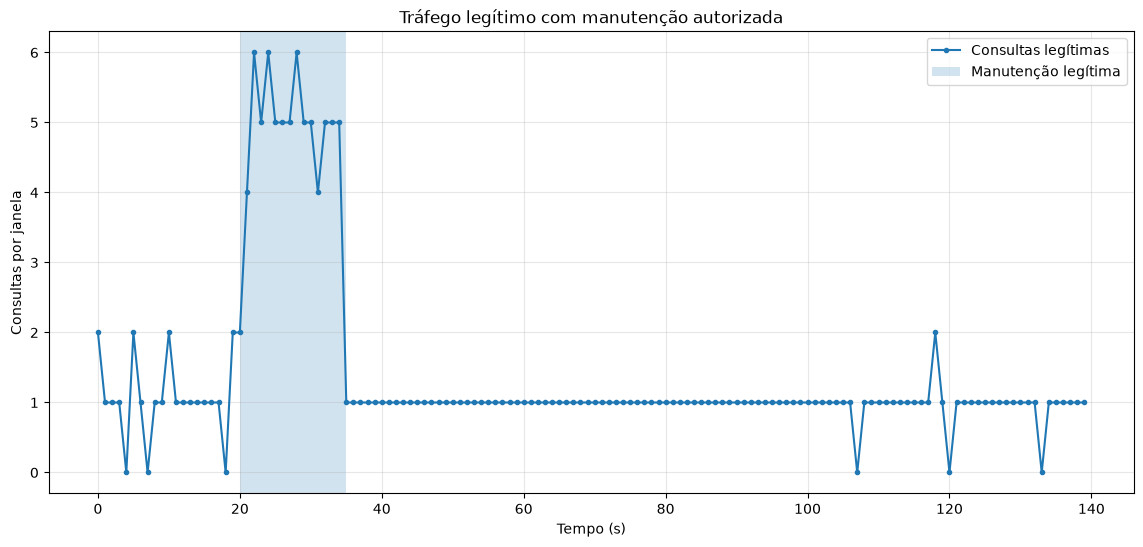

In [4]:
fig, ax = plt.subplots(
    figsize=(14, 6)
)

ax.plot(
    dados["segundo"],
    dados["consultas_cliente"],
    marker=".",
    linewidth=1.5,
    label="Consultas legítimas"
)

for _, atividade in atividades.iterrows():

    inicio = (
        atividade["inicio"]
        - inicio_ensaio
    )

    fim = (
        atividade["fim"]
        - inicio_ensaio
    )

    ax.axvspan(
        inicio,
        fim,
        alpha=0.2,
        label="Manutenção legítima"
    )

ax.set_title(
    "Tráfego legítimo com manutenção autorizada"
)

ax.set_xlabel("Tempo (s)")
ax.set_ylabel("Consultas por janela")

ax.legend()
ax.grid(alpha=0.3)

plt.show()